# PickNet: predicting (and simulating) human draft picks

The wheel model asks what the *other* seven drafters will take. This notebook models the drafter's own choice:
given the pack and everything seen so far, **which card does the human take?** A pick is a discrete choice
among exactly the cards in the pack, so every model outputs a softmax over the pack (a conditional logit, as in
DraftFM). The headline measures are **top-1 agreement** (the model's favourite card is the one the human took) and
**log loss per pick** (nats), on the same chronological test drafts (last 15%) as the wheel and deck models.

Models (`src/openlane/picknet.py`, trained by `scripts/train_picknet.py`):

| model | what it sees |
|---|---|
| `rating` | one learned number per card: a pick-order bot |
| `pool` | rating + a rank-d bilinear term between the candidate and the mean of the pool so far ("stay in your colours") |
| `picknet_nohist` | transformer: candidates attend to each other (which cards compete), state = pool bag + position + context |
| `picknet` | + a causal transformer over the whole draft so far: every pack seen, every pick, what the other seven took from packs that came back; candidates cross-attend to it |
| `picknet_big` | the same, d=192, 4 history + 3 pack layers |
| `multiset_zeroshot` | PickNet with **no card ids**: a card is only its features (colour, rarity, mana value, types, Scryfall rules features, a frozen rules-text embedding). Trained on 7 other sets, scored on MSH, which it never saw (DraftFM's "day zero" setup) |
| `multiset_plus_target` | the same features-only model, trained on the 7 sets + MSH's own training drafts |

Every model also gets per-draft context (rank, 17Lands skill buckets, days into the format), except `rating`.

Sections:
1. Results on MSH
2. Agreement through the draft
3. Who is predictable? Rank and skill
4. Every set: rating vs pool
5. Day zero: a set the model never saw
6. Simulating whole tables
7. Takeaways

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
from openlane.data import RANK_ORDER, load_tensors
from train_picknet import splits_for

SET = "MSH"
P = ROOT / "results" / f"{SET}.PremierDraft" / "picknet"
load = lambda n: json.loads((P / f"{n}.json").read_text()) if (P / f"{n}.json").exists() else None

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(30); pl.Config.set_fmt_str_lengths(40); pl.Config.set_tbl_width_chars(160)
MODELS = ["rating", "pool_d32", "pool_d64", "picknet_nohist", "picknet", "picknet_big", "multiset_zeroshot",
          "multiset_plus_target"]
res = {m: load(m) for m in MODELS if load(m)}

## 1. Results on MSH

10,292 test drafts, 432k picks. The last pick of each pack has one card left, so it is always "right"; DraftFM
reports agreement both with and without these forced picks, and so does this table. Uniform random would score
about 1/n per pick: 22% overall, 18% without forced picks.

In [2]:
def nonforced(m):
    z = np.load(P / f"test_{m}.npz") if (P / f"test_{m}.npz").exists() else None
    if z is None:  # every test draft has every pick, so the per-pick curves give the same means
        t1, nl = (np.array(res[m][k], float) for k in ("top1_by_pick", "nll_by_pick"))
        N = len(t1) // 3
        keep = np.ones(len(t1), bool)
        keep[N - 1::N] = False
        return t1[keep].mean(), nl[keep].mean()
    N = z["top1"].shape[1] // 3
    keep = np.ones(z["top1"].shape[1], bool)
    keep[N - 1::N] = False
    return z["top1"][:, keep].mean(), z["nll"][:, keep].mean()

rows = []
for m, r in res.items():
    nf1, nfl = nonforced(m)
    rows.append({"model": m, "params": r.get("params"), "top-1": r["top1"], "log loss": r["nll"],
                 "top-1 non-forced": nf1, "log loss non-forced": nfl,
                 "P1 / P2 / P3 top-1": f"{r['top1_p1']:.3f} / {r['top1_p2']:.3f} / {r['top1_p3']:.3f}"})
rows.append({"model": "DraftFM, MSH zero-shot (paper, d=128)", "params": 1_638_000, "top-1": 0.5671,
             "log loss": 1.1352, "top-1 non-forced": 0.5338, "log loss non-forced": None, "P1 / P2 / P3 top-1": ""})
tbl = pl.DataFrame(rows)
tbl.with_columns(pl.col("top-1", "log loss", "top-1 non-forced", "log loss non-forced").round(4))

model,params,top-1,log loss,top-1 non-forced,log loss non-forced,P1 / P2 / P3 top-1
str,i64,f64,f64,f64,f64,str
"""rating""",340,0.4973,1.324,0.4586,1.4258,"""0.533 / 0.489 / 0.470"""
"""pool_d32""",26036,0.644,0.9541,0.6166,1.0275,"""0.651 / 0.648 / 0.633"""
"""pool_d64""",51732,0.645,0.9519,0.6177,1.0251,"""0.652 / 0.649 / 0.634"""
"""picknet_nohist""",574849,0.6725,0.8551,0.6473,0.9209,"""0.677 / 0.677 / 0.663"""
"""picknet""",1301761,0.6821,0.8263,0.6576,0.8898,"""0.680 / 0.690 / 0.676"""
"""picknet_big""",3912577,0.6859,0.8151,0.6618,0.8778,"""0.684 / 0.693 / 0.680"""
"""multiset_zeroshot""",1400065,0.5075,1.411,0.4696,1.5196,"""0.481 / 0.520 / 0.522"""
"""multiset_plus_target""",1400065,0.6855,0.8102,0.6613,0.8725,"""0.684 / 0.693 / 0.680"""
"""DraftFM, MSH zero-shot (paper, d=128)""",1638000,0.5671,1.1352,0.5338,null,""""""


DraftFM's MSH numbers are over a different (earlier) slice of MSH drafts and pool Premier Draft drafts from the
whole format, so compare the size of the numbers, not the third decimal.

## 2. Agreement through the draft

Agreement is highest at the first pick of a pack (the best card is usually obvious) and at the end (few cards
left), and lowest in the middle, the same shape Ward et al. and DraftFM report. The gap between the models is
the interesting part: the context models gain most in the middle of each pack and in pack 2 and 3, when the
pool and what has been passed say most.

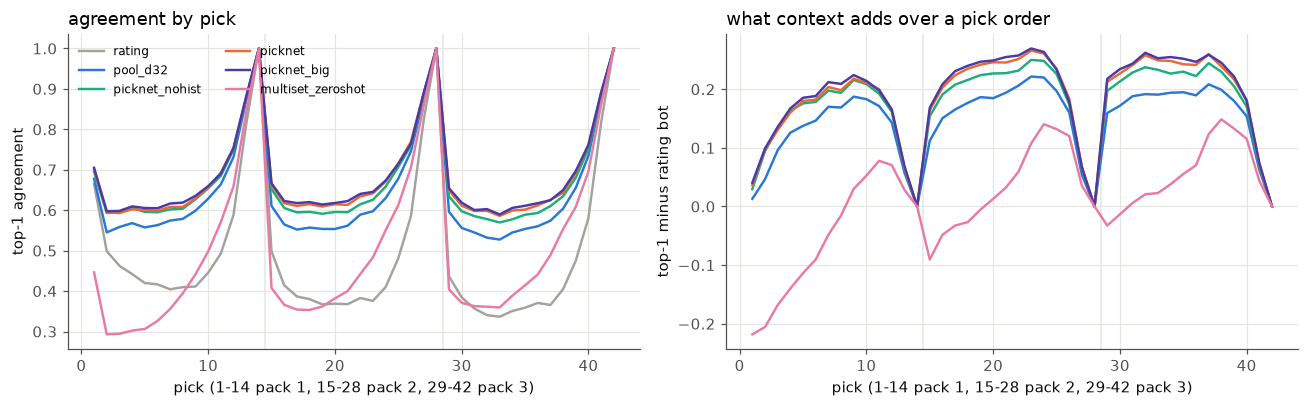

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
cols = {"rating": GRAY, "pool_d32": BLUE, "picknet_nohist": AQUA, "picknet": ORANGE, "picknet_big": VIOLET,
        "multiset_zeroshot": MAGENTA}
for m, c in cols.items():
    if m in res:
        t = np.array(res[m]["top1_by_pick"], float)
        ax[0].plot(np.arange(1, len(t) + 1), t, color=c, label=m, lw=1.6)
        if m != "rating" and "rating" in res:
            ax[1].plot(np.arange(1, len(t) + 1), t - np.array(res["rating"]["top1_by_pick"], float), color=c, lw=1.6)
N = len(res["rating"]["top1_by_pick"]) // 3
for a in ax:
    for k in (1, 2):
        a.axvline(k * N + 0.5, color=GRID, lw=1, zorder=0)
    a.set_xlabel("pick (1-14 pack 1, 15-28 pack 2, 29-42 pack 3)")
ax[0].set_ylabel("top-1 agreement"); ax[0].set_title("agreement by pick", loc="left")
ax[1].set_ylabel("top-1 minus rating bot"); ax[1].set_title("what context adds over a pick order", loc="left")
ax[0].legend(fontsize=8, ncol=2)
plt.tight_layout()

## 3. Who is predictable? Rank and skill

Agreement per test draft, grouped by the drafter's rank and their 17Lands game win-rate bucket.

In [4]:
t = load_tensors(SET)
te = splits_for(t, SET, "PremierDraft")["test"]
inv = {v: k for k, v in RANK_ORDER.items()} | {-1: "unknown"}
out = []
for m in ["rating", "pool_d32", "picknet"]:
    top = np.load(P / f"test_{m}.npz")["top1"].mean(1)
    for r in sorted(set(t.rank[te])):
        out.append({"model": m, "rank": inv[r], "drafts": int((t.rank[te] == r).sum()),
                    "top-1": float(top[t.rank[te] == r].mean())})
by_rank = pl.DataFrame(out).pivot(on="model", index=["rank", "drafts"], values="top-1")
by_rank

rank,drafts,rating,pool_d32,picknet
str,i64,f64,f64,f64
"""unknown""",489,0.509641,0.648895,0.690233
"""bronze""",274,0.475322,0.628519,0.6565
"""silver""",561,0.482217,0.635939,0.66098
"""gold""",910,0.477263,0.630324,0.66214
"""platinum""",3850,0.495145,0.639697,0.676815
"""diamond""",2572,0.506387,0.65105,0.693698
"""mythic""",1636,0.504468,0.654427,0.696414


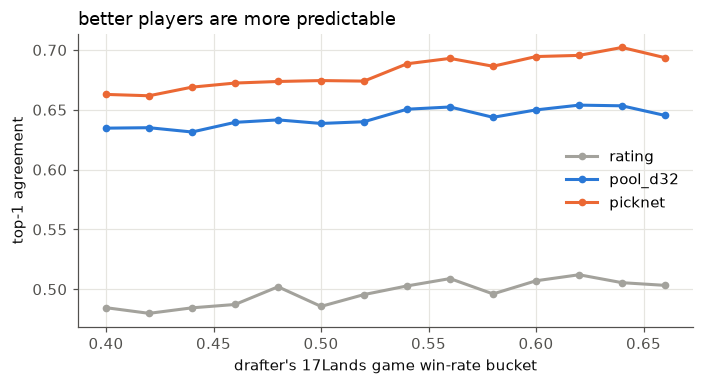

In [5]:
wr = t.user_wr[te]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for m, c in [("rating", GRAY), ("pool_d32", BLUE), ("picknet", ORANGE)]:
    top = np.load(P / f"test_{m}.npz")["top1"].mean(1)
    b = [x for x in sorted(set(wr)) if x >= 0 and (wr == x).sum() >= 200]
    ax.plot(b, [top[wr == x].mean() for x in b], "o-", color=c, label=m, ms=4)
ax.set_xlabel("drafter's 17Lands game win-rate bucket"); ax.set_ylabel("top-1 agreement")
ax.set_title("better players are more predictable", loc="left"); ax.legend()
plt.tight_layout()

## 4. Every set: rating vs pool

The two cheap models (a minute each) on all 14 sets with complete drafts. TLA's files lack P1P1, so its first
pick is not scored. Sets with 13-card packs (BLB, MKM, EOE, ECL) and LCI's 15-card packs work unchanged.

In [6]:
rows = []
for s in sorted(p.name.split(".")[0] for p in (ROOT / "results").glob("*.PremierDraft")):
    a, b = (ROOT / "results" / f"{s}.PremierDraft" / "picknet" / f"{n}.json" for n in ("rating", "pool_d32"))
    if a.exists() and b.exists():
        a, b = json.loads(a.read_text()), json.loads(b.read_text())
        rows.append({"set": s, "picks/pack": len(a["top1_by_pick"]) // 3, "rating top-1": a["top1"],
                     "pool top-1": b["top1"], "gain": b["top1"] - a["top1"], "rating NLL": a["nll"], "pool NLL": b["nll"]})
per_set = pl.DataFrame(rows).with_columns(pl.exclude("set", "picks/pack").round(4))
per_set

set,picks/pack,rating top-1,pool top-1,gain,rating NLL,pool NLL
str,i64,f64,f64,f64,f64,f64
"""BLB""",13,0.4519,0.6587,0.2068,1.4249,0.9152
"""DFT""",14,0.473,0.6498,0.1767,1.3699,0.9448
"""DSK""",14,0.4751,0.6646,0.1895,1.358,0.901
"""ECL""",13,0.4499,0.6685,0.2186,1.4134,0.8812
"""EOE""",13,0.4765,0.6506,0.174,1.3495,0.9377
"""FDN""",14,0.4833,0.666,0.1828,1.3549,0.9048
"""FIN""",14,0.4662,0.6507,0.1845,1.3908,0.9421
"""LCI""",15,0.4678,0.6433,0.1754,1.4121,0.9685
"""MKM""",13,0.4744,0.6442,0.1698,1.3635,0.9481


## 5. Day zero: a set the model never saw

`scripts/train_picknet_multiset.py`: PickNet with no card ids, so a card is only its 465 features (25 card
meta, 56 Scryfall rules features from `cardinfo.card_matrix`, 384 from a frozen `bge-small-en-v1.5` embedding
of the type line and rules text with the card's own name masked, from `scripts/card_text_embeddings.py`). Trained
on 20,000 random drafts from each of OTJ, DSK, FDN, DFT, TDM, FIN and SOS (5% held out for early stopping), 3
epochs, and scored on the MSH test drafts.

In [7]:
rows = []
for m in ["multiset_zeroshot", "multiset_plus_target", "picknet"]:
    if m in res:
        r = res[m]
        rows.append({"model": m, "trained on": ", ".join(r.get("sets", ["MSH"])), "top-1": r["top1"], "log loss": r["nll"],
                     "P1": r["top1_p1"], "P2": r["top1_p2"], "P3": r["top1_p3"],
                     "held-out val top-1 (training sets)": r["history"][-1]["val_top1"]})
pl.DataFrame(rows).with_columns(pl.col("top-1", "log loss", "P1", "P2", "P3").round(4))

model,trained on,top-1,log loss,P1,P2,P3,held-out val top-1 (training sets)
str,str,f64,f64,f64,f64,f64,f64
"""multiset_zeroshot""","""OTJ, DSK, FDN, DFT, TDM, FIN, SOS""",0.5075,1.411,0.4806,0.5198,0.5221,0.685741
"""multiset_plus_target""","""OTJ, DSK, FDN, DFT, TDM, FIN, SOS, MSH""",0.6855,0.8102,0.6836,0.693,0.68,0.685031
"""picknet""","""MSH""",0.6821,0.8263,0.6798,0.6903,0.6762,0.682071


## 6. Simulating whole tables

`scripts/simulate_draft.py` seats eight copies of a model at a table and drafts. The packs are real: each table
takes 8 random test drafts, and seat s opens the three packs that drafter opened, with that drafter's rank, skill
and date as context. Packs pass left, right, left. Each bot **samples** its pick from the model's softmax, so this
simulates human choices rather than playing the best card. 1,000 tables = 8,000 simulated drafts.

The simulated drafts are scored with the same statistics as the real test drafts (one 17Lands seat at a real
table):

* ATA and ALSA per card (cards taken 200+ times in the real drafts)
* the per-card wheel rate at picks 1-6. (The rate *by pick* is fixed by pack size: 6 of the 13 cards passed at
  pick 1 always come back, so it can't tell models apart.)
* **colour commitment**: of the drafter's last 14 picks, the share in their two main colours
* the share of drafters in each two-colour pair

In [8]:
rows = []
for m in ["rating", "pool_d32", "picknet", "picknet_big"]:
    f = P / f"sim_{m}.json"
    if f.exists():
        r = json.loads(f.read_text())
        rows.append({"bots": m, "ATA r": r["ata_corr"], "ATA MAE": r["ata_mae"], "ALSA r": r["alsa_corr"],
                     "wheel r (per card)": r["wheel_card_corr"], "wheel MAE": r["wheel_card_mae"],
                     "pack-3 picks in top-2 colours": r["commit_sim"], "real": r["commit_real"],
                     "colour-pair TV distance": r["pair_share_tv"], "P1P1 r": r["p1p1_corr"]})
sim = pl.DataFrame(rows).with_columns(pl.exclude("bots").round(3))
sim

bots,ATA r,ATA MAE,ALSA r,wheel r (per card),wheel MAE,pack-3 picks in top-2 colours,real,colour-pair TV distance,P1P1 r
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""rating""",0.989,0.441,0.99,0.984,0.029,0.559,0.815,0.15,0.875
"""pool_d32""",0.987,0.47,0.992,0.988,0.021,0.773,0.815,0.122,0.954
"""picknet""",0.979,0.526,0.965,0.954,0.05,0.802,0.815,0.066,0.973


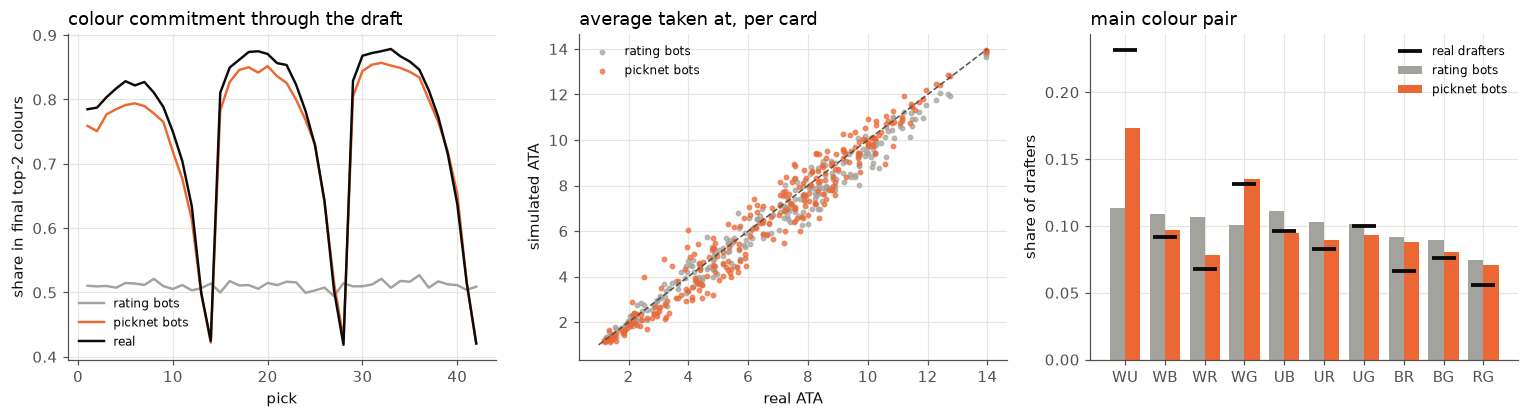

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
color = t.color_matrix / np.maximum(t.color_matrix.sum(1, keepdims=True), 1)  # colour weight of each card
for i, (m, c) in enumerate([("rating", GRAY), ("picknet", ORANGE)]):
    r = json.loads((P / f"sim_{m}.json").read_text())
    real, simd = r["pair_share_real"], r["pair_share_sim"]
    ax[2].bar(np.arange(10) + (i - 0.5) * 0.38, [simd[k] for k in real], 0.38, color=c, label=f"{m} bots")
ax[2].plot(np.arange(10), list(real.values()), "_", color=INK, ms=16, mew=2.5, label="real drafters")
ax[2].set_xticks(np.arange(10), list(real.keys())); ax[2].set_ylabel("share of drafters")
ax[2].set_title("main colour pair", loc="left"); ax[2].legend(fontsize=8)
for i, (m, c) in enumerate([("rating", GRAY), ("picknet", ORANGE)]):
    d = np.load(P / f"sim_{m}_drafts.npz")
    pick = d["pick"].astype(np.int64)
    G = pick.shape[0]
    T = pick.reshape(G, -1)
    col = color[T]                                  # [G, 42, 5]
    cum = np.cumsum(col, 1)
    top2 = np.argsort(-cum[:, -1], 1)[:, :2]
    share = np.take_along_axis(col, top2[:, None], -1).sum(-1) / np.maximum(col.sum(-1), 1e-9)
    ok = col.sum(-1) > 0
    ax[0].plot(np.arange(1, 43), np.nanmean(np.where(ok, share, np.nan), 0), color=c, label=f"{m} bots", lw=1.6)
realp = t.pick[te].reshape(len(te), -1).astype(np.int64)
col = color[realp]; top2 = np.argsort(-col.sum(1), 1)[:, :2]
share = np.take_along_axis(col, top2[:, None], -1).sum(-1) / np.maximum(col.sum(-1), 1e-9)
ax[0].plot(np.arange(1, 43), np.nanmean(np.where(col.sum(-1) > 0, share, np.nan), 0), color=INK, label="real", lw=1.6)
ax[0].set_xlabel("pick"); ax[0].set_ylabel("share in final top-2 colours")
ax[0].set_title("colour commitment through the draft", loc="left"); ax[0].legend(fontsize=8)
for m, c in [("rating", GRAY), ("picknet", ORANGE)]:
    pc = json.loads((P / f"sim_{m}.json").read_text()).get("per_card")
    if pc:
        ax[1].scatter(pc["ata_real"], pc["ata_sim"], s=8, color=c, alpha=0.7, label=f"{m} bots")
ax[1].plot([1, 14], [1, 14], color=MUTED, lw=1, ls="--")
ax[1].set_xlabel("real ATA"); ax[1].set_ylabel("simulated ATA"); ax[1].legend(fontsize=8)
ax[1].set_title("average taken at, per card", loc="left")
plt.tight_layout()

## 7. Takeaways

1. **PickNet predicts 68.2% of MSH test picks (big: 68.6%; features-only, pretrained on 7 other sets: 68.6%), against 49.7% for a pick-order bot and 64.4% for the
   bilinear pool model.** Log loss falls from 1.324 to 0.826 (big: 0.815) nats per pick. That is close to the
   ~70-71% reported for in-set models on other, larger sets (statistical-drafting, puder). Without forced last
   picks: 65.8% (big 66.2%).
2. **Where the gain comes from:** the pool is most of it (+14.7 points: stay in your colours), then the pack
   (+2.9: candidates attend to each other, so the model knows which cards compete), then the draft history
   (+0.9 points and −0.029 nats; the gain grows to +1.3 in pack 3). So the history of what was passed and what
   came back does help predict human picks, against puder's "+0.57% from pack contents".
3. **Better drafters are more predictable**, by about 4 points from Bronze to Mythic and across the 17Lands
   win-rate buckets, while the rating bot's agreement barely moves. Strong players converge on the same
   *contextual* pick, not just the same card ratings.
4. **Every set looks alike for the cheap models:** the pool model adds 15-22 points over a pick order on all 14
   sets, including 13- and 15-card packs.
5. **Day zero is hard.** With no card ids and 7 other sets (133k drafts), the features-only model gets 50.8% on
   MSH (non-forced 47.0%) against 68.6% on held-out drafts of the sets it trained on, and DraftFM's 56.7% with
   29 sets and 149M picks. The gap is largest at the first picks of each pack, where only card quality matters:
   judging power from rules text is the part that needs more sets.
   **Trained on those 7 sets plus MSH's own training drafts, the same features-only model is the best pick model
   in this notebook** (NLL 0.810, top-1 68.6%), ahead of PickNet with per-card ids (0.826) and level with the
   3x bigger id model (0.815). Shared card features plus other sets' drafts beat learning each card from scratch.
6. **As a simulator, PickNet drafts like people, and the cheap models don't.** Rating bots match per-card ATA and
   wheel rates well (those are marginal statistics, which a per-card rating fits directly) but only 56% of their
   pack-3 picks are in their two main colours (humans: 81.5%), and their colour pairs come out nearly uniform.
   PickNet bots commit like humans through every pack (0.80), pick P1P1 like humans (r = 0.97) and get the
   colour-pair mix closest (TV 0.066, pool 0.12, rating 0.15). All bots under-draft the format's most popular
   pair (WU: 23% of humans, 17% of PickNet bots): humans converge on the best archetype harder than a model that
   only imitates individual picks.
7. **Next:** temperature < 1 and a skill setting for the bots (sample as a Mythic drafter); use the simulator to
   produce wheel labels for the wheel model at all 8 seats; more sets (and the 13/15-card sets) for day zero.